# Матричная факторизация для рекомендаций

В предыдущих практиках рекомендации строились по популярности, описанию товара и сходству взаимодействий. Теперь каждая строка пользовательско-товарной матрицы будет представлена коротким вектором. Модель учится совместно размещать пользователей и товары в пространстве латентных факторов, а произведение двух векторов используется для ранжирования кандидатов.

Этот урок различает усечённое SVD матрицы взаимодействий и implicit ALS. Оба метода получают на вход ту же историю, но оптимизируют разные задачи. Для ALS показаны доверие к наблюдённым действиям, базовый вес ненаблюдённых пар, регуляризация, чередующиеся решения систем и динамика функции потерь. Ненаблюдённая пара не считается доказанным отказом.

Практическая цель — сравнить методы по покупкам следующего месяца без утечки будущего: настроить параметры только на апрельской валидации, затем заново обучить выбранные конфигурации на истории до мая и один раз оценить май. Все взаимодействия и характеристики коллекций в наборе синтетические; численные результаты показывают поведение учебного протокола, а не качество для реального магазина.

## Общий протокол и матрица

Матричная факторизация начинается не с выбора ранга, а с определения того, какие действия модель имеет право видеть. История содержит события строго до временной границы. Покупки следующего месяца служат целевыми товарами при оценке. Такой порядок имитирует задачу рекомендации в момент принятия решения. Если перемешать события и случайно оставить будущий просмотр в обучении, сравнение моделей станет искусственно лёгким.

Матрица R имеет форму 300 × 180. Её элемент равен log1p суммы весов событий для соответствующей пары: просмотр даёт один, корзина три, покупка пять. Логарифм уменьшает влияние многократных действий, не стирая порядок сильных и слабых наблюдений. Матрица B показывает лишь факт взаимодействия. Обе нужны: R задаёт уверенность ALS, B выделяет наблюдённые пары и маску уже известных товаров. Реестр пользователей содержит известные идентификаторы даже для строки без истории, но сами числа в модель не передаются.

Стартовая ячейка находит каталог модуля и выводит его имя. Она не загружает данные и не обучает модель. Это сохранённый ориентир для последующих относительных путей.

In [1]:
# Шаг М4.04.01 — Импорты и расположение данных
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
module_name = "Модуль 4 Рекомендательные системы"
candidates = [candidate for root in [Path.cwd(), *Path.cwd().parents]
              for candidate in (root, root / "course" / "practice" / module_name)]
MODULE_DIR = next(p for p in candidates if p.name == module_name and p.is_dir())
DATA_DIR = MODULE_DIR / "data"
SOURCE_DIR = MODULE_DIR.parent.parent / "data"
print("Каталог материалов:", MODULE_DIR.name)

Каталог материалов: Модуль 4 Рекомендательные системы


Функции не возвращают вывод при определении. Сохранённое состояние позволяет воспроизвести одинаковую временную границу, маску увиденного и оценку для всех следующих моделей.

In [2]:
# Шаг М4.04.02 — Функции временного протокола
def load_context(phase="validation"):
    if phase not in {"validation", "test"}:
        raise ValueError("Ожидается validation или test")
    catalog = pd.read_csv(DATA_DIR / "reco_catalog.csv").sort_values("product_id").reset_index(drop=True)
    events = pd.read_csv(DATA_DIR / "reco_events.csv", parse_dates=["timestamp"]).drop_duplicates("event_id")
    cut = pd.Timestamp("2025-04-01" if phase == "validation" else "2025-05-01")
    end = pd.Timestamp("2025-05-01" if phase == "validation" else "2025-06-01")
    history = events[events.timestamp < cut].copy()
    future = events[(events.timestamp >= cut) & (events.timestamp < end) & (events.event_type == "purchase")]
    user_ids = np.arange(1, 301)  # Известный учебный реестр, а не признак предпочтения.
    item_ids = catalog.product_id.to_numpy()
    u_map = {int(value): index for index, value in enumerate(user_ids)}
    i_map = {int(value): index for index, value in enumerate(item_ids)}
    history["strength"] = history.event_type.map({"view": 1.0, "cart": 3.0, "purchase": 5.0})
    pairs = history.groupby(["user_id", "product_id"]).strength.sum().reset_index()
    R = sparse.csr_matrix((np.log1p(pairs.strength),
                           (pairs.user_id.map(u_map), pairs.product_id.map(i_map))),
                          shape=(len(user_ids), len(item_ids)))
    B = R.copy()
    B.data[:] = 1.0
    seen = B.toarray().astype(bool)  # Только 300 x 180; полный большой каталог так не разворачивается.
    truth = {int(u): set(g.product_id) - set(item_ids[seen[u_map[int(u)]]])
             for u, g in future.groupby("user_id")}
    purchases = history[history.event_type.eq("purchase")].drop_duplicates(["user_id", "product_id"])
    popularity = purchases.groupby("product_id").size().reindex(item_ids, fill_value=0).to_numpy(float)
    return dict(catalog=catalog, events=events, history=history, R=R, B=B, seen=seen,
                truth=truth, user_ids=user_ids, item_ids=item_ids, u_map=u_map,
                i_map=i_map, popularity=popularity, cut=cut, end=end, phase=phase)

def top_indices(scores, seen, k=10):
    values = np.array(scores, dtype=float, copy=True)
    if values.ndim != 2 or values.shape != seen.shape or not np.isfinite(values).all():
        raise ValueError("Нужна конечная матрица оценок формы user x item")
    values[seen] = -np.inf
    result = []
    for row in values:
        order = np.argsort(-row, kind="stable")
        result.append(order[np.isfinite(row[order])][:k])
    return result

def evaluate(scores, ctx, k=10):
    ranked = top_indices(scores, ctx["seen"], k)
    rows = []
    for u, relevant in ctx["truth"].items():
        if not relevant:
            continue
        ui = ctx["u_map"][u]
        recommended = ctx["item_ids"][ranked[ui]]
        hits = np.isin(recommended, list(relevant)).astype(float)
        discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
        ideal = (1 / np.log2(np.arange(2, min(k, len(relevant)) + 2))).sum()
        positions = np.flatnonzero(hits)
        rows.append(dict(user_id=u, history_size=int(ctx["seen"][ui].sum()), n_truth=len(relevant),
                         precision=float(hits.sum()/k), recall=float(hits.sum()/len(relevant)),
                         ndcg=float(hits @ discounts / ideal), hit=float(hits.any()),
                         mrr=0.0 if not len(positions) else 1.0/(positions[0]+1)))
    return pd.DataFrame(rows)

def summarize(scores, ctx, k=10):
    detail = evaluate(scores, ctx, k)
    ranked = top_indices(scores, ctx["seen"], k)
    evaluated_rows = [ranked[ctx["u_map"][int(u)]] for u in detail.user_id]
    chosen = np.concatenate(evaluated_rows)
    novelty = -np.log2((ctx["popularity"]+1)/(ctx["popularity"].sum()+len(ctx["item_ids"])))
    return pd.Series({"Precision@K":detail.precision.mean(), "Recall@K":detail.recall.mean(),
                      "NDCG@K":detail.ndcg.mean(), "HitRate@K":detail.hit.mean(),
                      "Coverage":len(np.unique(chosen))/len(ctx["item_ids"]),
                      "Novelty":float(novelty[chosen].mean()), "users":len(detail)})

def popular_scores(ctx):
    return np.tile(ctx["popularity"], (len(ctx["user_ids"]), 1))

Таблица аудита фиксирует размеры каталога, реестра, уникальных событий, обучающей истории и валидационной цели. Она нужна для чтения следующих метрик в контексте конкретного учебного набора.

In [3]:
# Шаг М4.04.03 — Валидационный контекст и аудит
val = load_context("validation")
audit = pd.Series({"товаров в каталоге": len(val["item_ids"]),
                   "пользователей в реестре": len(val["user_ids"]),
                   "событий после удаления дублей": len(val["events"]),
                   "событий истории": len(val["history"]),
                   "пар с взаимодействием": val["R"].nnz,
                   "пользователей с новой апрельской покупкой": sum(bool(x) for x in val["truth"].values())})
display(audit.to_frame("значение"))

,значение
товаров в каталоге,180
пользователей в реестре,300
событий после удаления дублей,11234
событий истории,5924
пар с взаимодействием,5040
пользователей с новой апрельской покупкой,290


Таблица связывает внешний product_id с индексом столбца и исходными атрибутами товара. Последняя строка подчёркивает, что числовой ключ не является индексом массива.

In [4]:
# Шаг М4.04.04 — Ключи товаров и индексы матрицы
keys = val["catalog"][["product_id", "name", "category", "price"]].copy()
keys.insert(0, "индекс столбца", np.arange(len(keys)))
display(keys.head(8))
print("Пример внешнего ключа и позиции:", int(keys.iloc[-1].product_id), int(keys.iloc[-1]["индекс столбца"]))

,индекс столбца,product_id,name,category,price
0,0,1,Электроника товар 1,Электроника,61790
1,1,2,Обувь товар 2,Обувь,15690
2,2,3,Электроника товар 3,Электроника,29120
3,3,4,Книги товар 4,Книги,1760
4,4,5,Продукты товар 5,Продукты,1680
5,5,6,Продукты товар 6,Продукты,2320
6,6,7,Продукты товар 7,Продукты,1790
7,7,8,Бытовая техника товар 8,Бытовая техника,56240


Пример внешнего ключа и позиции: 388 179


Вывод закрепляет временную границу валидации. Утверждение о последнем событии истории подтверждает отсутствие событий из целевого апреля в обучающей матрице.

In [5]:
# Шаг М4.04.05 — Проверка временной границы
print("История заканчивается до", val["cut"].date(),
      "; последний момент:", val["history"].timestamp.max())
print("Целевое окно:", val["cut"].date(), "—", val["end"].date())
assert val["history"].timestamp.max() < val["cut"]

История заканчивается до 2025-04-01 ; последний момент: 2025-03-31 23:55:17
Целевое окно: 2025-04-01 — 2025-05-01


Сохранены форма, доля наблюдённых пар и шкала весов. Плотный массив используется здесь только из-за учебных 300 × 180; переносить это решение на большой каталог без оценки памяти нельзя.

In [6]:
# Шаг М4.04.06 — Плотность и шкала сигналов
R_dense = val["R"].toarray()
print("Форма R:", R_dense.shape, "плотность:", round(val["R"].nnz / R_dense.size, 4))
print("Ненулевые значения R, квантили:", np.round(np.quantile(val["R"].data, [0, .25, .5, .75, 1]), 3))
print("B содержит только:", np.unique(val["B"].data))

Форма R: (300, 180) плотность: 0.0933
Ненулевые значения R, квантили: [0.693 0.693 1.386 1.792 1.946]
B содержит только: [1.]


Первый график сохраняет карту B. Он делает видимой разреженность и помогает отличать пропущенное взаимодействие от отрицательного отзыва.

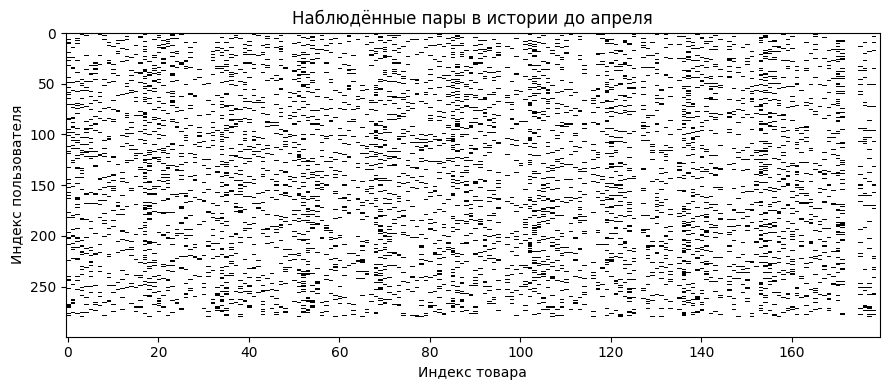

In [7]:
# Шаг М4.04.07 — Карта наблюдённых пар
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(val["seen"], aspect="auto", interpolation="nearest", cmap="Greys")
ax.set(xlabel="Индекс товара", ylabel="Индекс пользователя", title="Наблюдённые пары в истории до апреля")
plt.tight_layout()
plt.show()

## Латентные факторы и контрольное SVD

В модели ранга k пользователь u получает вектор x_u длины k, а товар i — вектор y_i той же длины. Оценка пары — их скалярное произведение. Параметры ищутся совместно на всей матрице, поэтому два пользователя могут оказаться близко в факторном пространстве даже без полностью одинаковых списков покупок. Ранг ограничивает число степеней свободы: слишком маленький сглаживает различия, слишком большой может подстроиться под случайные события.

Координата фактора не является готовой темой вроде «обувь» или «дорогой товар». Пространство можно поворачивать, а направления компонент менять знаком при согласованном изменении обеих сторон. Смысл имеет восстановленное произведение и проверенное ранжирование. Регуляризация в ALS ограничит длины векторов. Сначала, однако, используется TruncatedSVD как контрольный алгоритм низкорангового приближения R. Он не решает задачу взвешенных неявных предпочтений.

Вывод сохраняет три скалярных произведения. Он показывает, как короткие векторы дают сравнимые баллы, но сами координаты не имеют названий категорий.

In [8]:
# Шаг М4.04.08 — Скалярное произведение на двух векторах
example_user = np.array([0.8, -0.2])
example_items = np.array([[0.7, 0.1], [0.1, -0.9], [-0.4, 0.3]])
print("Баллы трёх условных товаров:", np.round(example_items @ example_user, 3))

Баллы трёх условных товаров: [ 0.54  0.26 -0.38]


Сохранены формы проекции и оценок и первая таблица метрик SVD. Наблюдённый результат нужен как контрольная точка перед настройкой ранга.

In [9]:
# Шаг М4.04.09 — Первое усечённое SVD
svd = TruncatedSVD(n_components=16, random_state=42)
user_projection = svd.fit_transform(val["R"])
svd_raw = user_projection @ svd.components_
svd_scores = svd_raw.copy()
svd_scores[np.asarray(val["B"].sum(axis=1)).ravel() == 0] = val["popularity"]
print("Формы факторов и оценок:", user_projection.shape, svd.components_.shape, svd_scores.shape)
display(summarize(svd_scores, val).round(4).to_frame("SVD, ранг 16"))

Формы факторов и оценок: (300, 16) (16, 180) (300, 180)


,"SVD, ранг 16"
Precision@K,0.0945
Recall@K,0.2362
NDCG@K,0.1977
HitRate@K,0.6966
Coverage,0.9389
Novelty,7.2732
users,290.0000


Сохранена конкретная выдача SVD с исходными полями каталога. Видно, что ранжирование использует баллы, а отображение — реальные атрибуты товаров.

In [10]:
# Шаг М4.04.10 — Первые кандидаты SVD для одного пользователя
u = int(val["user_ids"][np.flatnonzero(val["seen"].sum(axis=1) > 0)[0]])
idx = top_indices(svd_scores, val["seen"])[val["u_map"][u]]
display(val["catalog"].iloc[idx][["product_id", "name", "category", "price"]].assign(
    score=np.round(svd_scores[val["u_map"][u], idx], 3)))
print("Пользователь:", u, "ранее видел:", int(val["seen"][val["u_map"][u]].sum()))

,product_id,name,category,price,score
19,20,Продукты товар 20,Продукты,1140,0.813
72,73,Продукты товар 73,Продукты,2750,0.707
6,7,Продукты товар 7,Продукты,1790,0.615
37,38,Продукты товар 38,Продукты,980,0.600
38,39,Продукты товар 39,Продукты,1550,0.578
153,214,Спорт товар 214,Спорт,5190,0.509
53,54,Дом и сад товар 54,Дом и сад,21090,0.399
98,101,Продукты товар 101,Продукты,1290,0.374
114,119,Продукты товар 119,Продукты,2300,0.361
34,35,Одежда товар 35,Одежда,7310,0.342


Пользователь: 1 ранее видел: 18


Таблица сравнивает три ранга SVD на одном временном окне. Значение лучшего ранга будет перенесено в майский refit без просмотра майских метрик во время настройки.

In [11]:
# Шаг М4.04.11 — Сетка рангов SVD на апреле
svd_rows = []
for rank in [8, 16, 32]:
    model = TruncatedSVD(n_components=rank, random_state=42)
    scores = model.fit_transform(val["R"]) @ model.components_
    scores[np.asarray(val["B"].sum(axis=1)).ravel() == 0] = val["popularity"]
    metrics = summarize(scores, val)
    svd_rows.append({"rank": rank, **metrics.to_dict()})
svd_grid = pd.DataFrame(svd_rows).sort_values("NDCG@K", ascending=False)
display(svd_grid.round(4))

,rank,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
1,16,0.0945,0.2362,0.1977,0.6966,0.9389,7.2732,290.0
0,8,0.0986,0.2466,0.1957,0.7069,0.8722,7.2502,290.0
2,32,0.0748,0.1871,0.1526,0.5655,0.9500,7.3529,290.0


Второй график сохраняет зависимость апрельского NDCG@10 от трёх проверенных рангов SVD. Он иллюстрирует процедуру настройки, не заменяя финальную проверку.

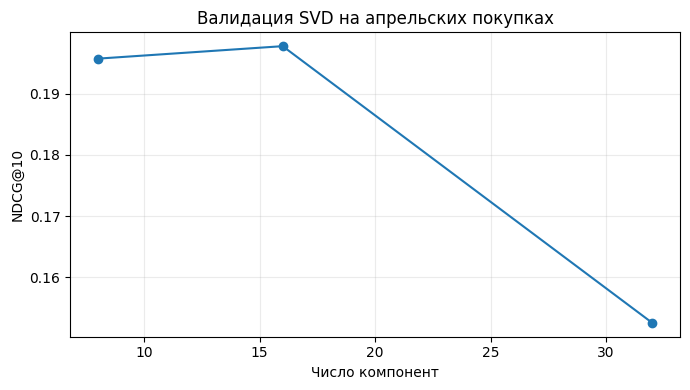

In [12]:
# Шаг М4.04.12 — График качества SVD по рангу
fig, ax = plt.subplots(figsize=(7, 4))
ordered_svd = svd_grid.sort_values("rank")
ax.plot(ordered_svd["rank"], ordered_svd["NDCG@K"], marker="o")
ax.set(xlabel="Число компонент", ylabel="NDCG@10", title="Валидация SVD на апрельских покупках")
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Implicit ALS: предпочтение, доверие и потери

Для неявных событий нет числовой оценки товара пользователем. В ALS вводится предпочтение p_ui: оно равно единице при наличии хотя бы одного действия и нулю для пропущенной пары. Уверенность c_ui равна 1 + alpha × R_ui. Таким образом, пропущенная пара получает c=1, а наблюдённая — более высокий вес. Ноль в p для пропуска является технической частью функции потерь, а не утверждением, что пользователю товар не нравится.

Оптимизируется сумма c_ui(p_ui − x_u·y_i)² по всем парам плюс lambda, умноженная на сумму квадратов всех факторов. Попеременно фиксируется одна сторона и решается маленькая система для каждого вектора другой стороны. Эта версия предназначена для матрицы 300 × 180: в учебных целях R разворачивается в плотный массив. Код сохраняет значение той же целевой функции после полного прохода по обеим сторонам, что позволяет проверить ход обучения. Параметры alpha, lambda и ранг настраиваются только по будущим апрельским покупкам.

Ячейка определяет als_fit и als_scores. Печатного результата у определения нет; сохранённый результат состоит в доступных функциях и явной формуле обновления факторов.

In [13]:
# Шаг М4.04.13 — Определение учебного implicit ALS
def als_fit(ctx, rank=16, regularization=0.1, alpha=15.0, iterations=10, seed=42):
    """Обучение учебной implicit ALS на небольшом наборе взаимодействий."""
    if rank < 1 or regularization <= 0 or alpha < 0 or iterations < 1:
        raise ValueError("Проверьте ранг, регуляризацию, alpha и число итераций")
    R = ctx["R"].toarray()
    P = (R > 0).astype(float)
    n_users, n_items = R.shape
    rng = np.random.default_rng(seed)
    X = np.zeros((n_users, rank))
    Y = rng.normal(0, 0.1, size=(n_items, rank))
    eye = np.eye(rank)
    losses = []

    for _ in range(iterations):
        yty = Y.T @ Y
        for u in range(n_users):
            observed = np.flatnonzero(P[u])
            if not len(observed):
                X[u] = 0.0
                continue
            factors = Y[observed]
            confidence = 1.0 + alpha * R[u, observed]
            lhs = yty + factors.T @ ((confidence - 1.0)[:, None] * factors)
            X[u] = np.linalg.solve(lhs + regularization * eye,
                                   factors.T @ confidence)

        xtx = X.T @ X
        for i in range(n_items):
            observed = np.flatnonzero(P[:, i])
            if not len(observed):
                Y[i] = 0.0
                continue
            factors = X[observed]
            confidence = 1.0 + alpha * R[observed, i]
            lhs = xtx + factors.T @ ((confidence - 1.0)[:, None] * factors)
            Y[i] = np.linalg.solve(lhs + regularization * eye,
                                   factors.T @ confidence)

        residual = P - X @ Y.T
        loss = np.square(residual).sum()
        loss += alpha * (R * np.square(residual)).sum()
        loss += regularization * (np.square(X).sum() + np.square(Y).sum())
        losses.append(float(loss))

    return {"user_factors": X, "item_factors": Y, "loss": losses,
            "rank": rank, "regularization": regularization, "alpha": alpha}


def als_scores(model, ctx):
    """Оценки известных пар и популярность для пользователей без истории."""
    scores = model["user_factors"] @ model["item_factors"].T
    if scores.shape != ctx["seen"].shape:
        raise ValueError("Размер факторов не соответствует контексту")
    cold = np.asarray(ctx["B"].sum(axis=1)).ravel() == 0
    scores[cold] = ctx["popularity"]
    return scores

Таблица сохраняет p и c для наблюдённой и пропущенной пары. Она конкретизирует роль базового доверия один и повышенного доверия к действию.

In [14]:
# Шаг М4.04.14 — Предпочтение и доверие на конкретных парах
observed_u, observed_i = val["R"].nonzero()
first_u, first_i = int(observed_u[0]), int(observed_i[0])
missing_u, missing_i = np.argwhere(~val["seen"])[0]
confidence_example = pd.DataFrame([
    {"пара": "наблюдённая", "R": R_dense[first_u, first_i], "p": 1.0, "c при alpha=15": 1+15*R_dense[first_u, first_i]},
    {"пара": "без события", "R": R_dense[missing_u, missing_i], "p": 0.0, "c при alpha=15": 1+15*R_dense[missing_u, missing_i]},
])
display(confidence_example.round(3))

,пара,R,p,c при alpha=15
0,наблюдённая,1.792,1.0,27.876
1,без события,0.000,0.0,1.000


Таблица сохраняет ход оптимизации и проверку невозрастания целевой функции. Это диагностика корректности ALS, а не финальная метрика рекомендаций.

In [15]:
# Шаг М4.04.15 — Первое обучение ALS и значения потерь
als_demo = als_fit(val, rank=16, regularization=0.1, alpha=15, iterations=8, seed=42)
print("Размеры факторов:", als_demo["user_factors"].shape, als_demo["item_factors"].shape)
display(pd.DataFrame({"проход": np.arange(1, 9), "loss": als_demo["loss"]}).round(2))
print("Потери не возрастают:", bool(np.all(np.diff(als_demo["loss"]) <= 1e-7)))

Размеры факторов: (300, 16) (180, 16)


,проход,loss
0,1,23656.96
1,2,13106.58
2,3,11773.62
3,4,11188.40
4,5,10853.79
5,6,10637.59
6,7,10489.07
7,8,10381.63


Потери не возрастают: True


Третий график сохраняет траекторию loss для одной конфигурации ALS. Он подтверждает работу чередующихся обновлений на учебном наборе.

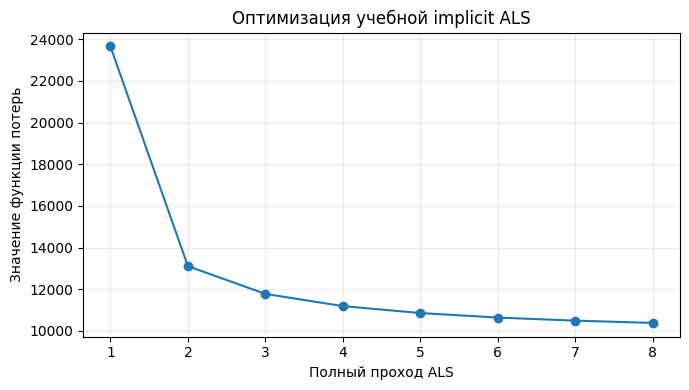

In [16]:
# Шаг М4.04.16 — Кривая функции потерь ALS
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(als_demo["loss"])+1), als_demo["loss"], marker="o")
ax.set(xlabel="Полный проход ALS", ylabel="Значение функции потерь", title="Оптимизация учебной implicit ALS")
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

Сохранена валидационная таблица первой конфигурации ALS. Она отделяет качество ранжирования от убывания обучающей функции потерь.

In [17]:
# Шаг М4.04.17 — Первая оценка ALS на апреле
als_demo_scores = als_scores(als_demo, val)
display(summarize(als_demo_scores, val).round(4).to_frame("ALS, пример"))

,"ALS, пример"
Precision@K,0.0693
Recall@K,0.1733
NDCG@K,0.1308
HitRate@K,0.5345
Coverage,0.9500
Novelty,7.3261
users,290.0000


## Настройка на апреле и фиксация решения

Для настройки проверяются два ранга, два значения регуляризации и два значения alpha. Это восемь конфигураций ALS. Все они видят одну и ту же историю до апреля и оцениваются по одним покупкам апреля. Число проходов и seed фиксированы. Затем лучшая конфигурация внутри метода выбирается по NDCG@10, а общий кандидат сравнивается с SVD и простой популярностью. При равенстве метрики порядок в таблице фиксирован, чтобы процедура была воспроизводимой.

Такая настройка не даёт статистической гарантии качества. Валидационный месяц невелик, а сами события синтетические. Однако порядок действий важен: майские покупки нельзя использовать для подбора ранга, alpha, регуляризации или метода. После выбора параметры замораживаются. На майской фазе обучение запускается заново на истории до первого мая, и только затем вычисляется тестовая метрика на покупках мая.

Таблица сохраняет все восемь конфигураций ALS и их апрельские метрики. Сортировка фиксирует правило выбора по NDCG@10.

In [18]:
# Шаг М4.04.18 — Сетка параметров ALS
als_rows = []
for rank in [8, 16]:
    for regularization in [0.1, 1.0]:
        for alpha in [5.0, 15.0]:
            model = als_fit(val, rank=rank, regularization=regularization,
                            alpha=alpha, iterations=8, seed=42)
            metrics = summarize(als_scores(model, val), val)
            als_rows.append({"rank": rank, "regularization": regularization,
                             "alpha": alpha, "loss_start": model["loss"][0],
                             "loss_end": model["loss"][-1], **metrics.to_dict()})
als_grid = pd.DataFrame(als_rows).sort_values(
    ["NDCG@K", "rank", "regularization", "alpha"],
    ascending=[False, True, True, True]).reset_index(drop=True)
display(als_grid.round(4))

,rank,regularization,alpha,loss_start,loss_end,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
0,16,1.0,5.0,15474.8002,8255.0656,0.0838,0.2095,0.1617,0.6345,0.9500,7.3496,290.0
1,16,0.1,5.0,13623.0677,7464.6257,0.0817,0.2043,0.1569,0.6207,0.9500,7.3432,290.0
2,8,1.0,5.0,23679.8688,11574.2150,0.0817,0.2043,0.1564,0.5931,0.9389,7.2551,290.0
3,8,0.1,5.0,22663.9455,10963.3842,0.0814,0.2034,0.1543,0.6069,0.9389,7.2526,290.0
4,16,0.1,15.0,23656.9582,10381.6269,0.0693,0.1733,0.1308,0.5345,0.9500,7.3261,290.0
5,16,1.0,15.0,28839.3971,12264.0642,0.0683,0.1707,0.1280,0.5241,0.9500,7.3346,290.0
6,8,1.0,15.0,52730.7653,17796.5453,0.0641,0.1603,0.1240,0.5103,0.9500,7.2985,290.0
7,8,0.1,15.0,49717.3008,16239.8823,0.0617,0.1543,0.1189,0.4931,0.9500,7.3023,290.0


Сохранена запись выбранных рангов, регуляризации, alpha и числа проходов. Она служит точкой заморозки настроек перед тестом.

In [19]:
# Шаг М4.04.19 — Параметры, выбранные до теста
best_svd_rank = int(svd_grid.iloc[0]["rank"])
best_als = als_grid.iloc[0]
selected = {"svd_rank": best_svd_rank,
            "als_rank": int(best_als["rank"]),
            "als_regularization": float(best_als["regularization"]),
            "als_alpha": float(best_als["alpha"]),
            "als_iterations": 8, "seed": 42}
display(pd.Series(selected).to_frame("зафиксировано"))

,зафиксировано
svd_rank,16.0
als_rank,16.0
als_regularization,1.0
als_alpha,5.0
als_iterations,8.0
seed,42.0


Валидационная таблица показывает простой базовый метод и лучшие настройки SVD и ALS. Она позволяет выбрать метод до просмотра мая.

In [20]:
# Шаг М4.04.20 — Сравнение с популярностью на валидации
popular_val = summarize(popular_scores(val), val)
validation_compare = pd.DataFrame({
    "Популярность": popular_val,
    "SVD": svd_grid.iloc[0][popular_val.index],
    "implicit ALS": als_grid.iloc[0][popular_val.index],
}).T
display(validation_compare.round(4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
Популярность,0.0303,0.0759,0.0608,0.2724,0.1000,6.4356,290.0
SVD,0.0945,0.2362,0.1977,0.6966,0.9389,7.2732,290.0
implicit ALS,0.0838,0.2095,0.1617,0.6345,0.9500,7.3496,290.0


Вывод фиксирует имя метода и его апрельский NDCG@10. На этом этапе настройка завершена; май остаётся закрытым.

In [21]:
# Шаг М4.04.21 — Выбор метода по NDCG@10
chosen_method = str(validation_compare["NDCG@K"].astype(float).idxmax())
print("Метод, выбранный на апреле:", chosen_method)
print("Апрельский NDCG@10:", round(float(validation_compare.loc[chosen_method, "NDCG@K"]), 4))

Метод, выбранный на апреле: SVD
Апрельский NDCG@10: 0.1977


## Проверка выдачи и границ применимости

Факторные оценки существуют только для пользователей и товаров, включённых в обучающую матрицу. Если пользователь есть в учебном реестре, но не совершал действий до границы, персональный вектор не выучен и применяется популярность. Пользователь вне реестра также требует отдельной стратегии популярности или сбора первых сигналов. Новый товар без обучающих событий не получает содержательного латентного вектора; для его продвижения нужны описание, редакторское правило или период накопления сигналов. Неизвестный ключ товара нельзя подставлять как индекс матрицы.

Проверка конкретной выдачи нужна ещё и для маски уже увиденного. Даже удачно восстановленные исторические пары не подходят под сформулированную задачу новых покупок. Метрики Top-N отличаются от RMSE по восстановленным записям: малая квадратичная ошибка на истории не гарантирует правильных первых десяти кандидатов. В данных с явными рейтингами предпочтения могли бы хранить разные целевые значения, а отсутствие рейтинга всё равно требовало бы отдельной трактовки, не автоматически отрицательной оценки.

Сохранена конкретная выдача ALS и выполнена проверка маски истории. Таблица позволяет увидеть реальные product_id, названия, категории и цены предлагаемых товаров.

In [22]:
# Шаг М4.04.22 — Выдача ALS без просмотренного
best_val_als_model = als_fit(val, rank=selected["als_rank"],
    regularization=selected["als_regularization"], alpha=selected["als_alpha"],
    iterations=selected["als_iterations"], seed=selected["seed"])
best_val_scores = als_scores(best_val_als_model, val)
ui = val["u_map"][u]
recommended_idx = top_indices(best_val_scores, val["seen"])[ui]
assert not val["seen"][ui, recommended_idx].any()
display(val["catalog"].iloc[recommended_idx][["product_id", "name", "category", "price"]].assign(
    score=np.round(best_val_scores[ui, recommended_idx], 3)))

,product_id,name,category,price,score
19,20,Продукты товар 20,Продукты,1140,0.900
153,214,Спорт товар 214,Спорт,5190,0.861
6,7,Продукты товар 7,Продукты,1790,0.825
53,54,Дом и сад товар 54,Дом и сад,21090,0.796
80,81,Одежда товар 81,Одежда,4900,0.729
119,127,Электроника товар 127,Электроника,14280,0.702
72,73,Продукты товар 73,Продукты,2750,0.627
20,21,Одежда товар 21,Одежда,6280,0.620
54,55,Одежда товар 55,Одежда,1430,0.619
137,169,Красота товар 169,Красота,7430,0.580


Сохранены размеры и медианные длины векторов. Вывод формы подтверждает, что произведение факторов возвращает оценки 300 × 180.

In [23]:
# Шаг М4.04.23 — Смысл факторных координат
factor_norms = pd.DataFrame({"сторона": ["пользователи", "товары"],
    "число векторов": [len(best_val_als_model["user_factors"]), len(best_val_als_model["item_factors"])],
    "медианная длина": [np.median(np.linalg.norm(best_val_als_model["user_factors"], axis=1)),
                          np.median(np.linalg.norm(best_val_als_model["item_factors"], axis=1))]})
display(factor_norms.round(3))
print("Проверка формы произведения:", (best_val_als_model["user_factors"] @ best_val_als_model["item_factors"].T).shape)

,сторона,число векторов,медианная длина
0,пользователи,300,1.831
1,товары,180,0.828


Проверка формы произведения: (300, 180)


Вывод фиксирует число пустых строк, работу fallback для них и отсутствие латентных координат у неизвестных внешних ключей.

In [24]:
# Шаг М4.04.24 — Холодный пользователь и неизвестные ключи
cold_rows = np.flatnonzero(np.asarray(val["B"].sum(axis=1)).ravel() == 0)
print("Пользователей без истории:", len(cold_rows))
if len(cold_rows):
    cold_ui = int(cold_rows[0])
    print("Fallback совпал с популярностью:", np.allclose(best_val_scores[cold_ui], val["popularity"]))
unknown_user = int(val["user_ids"].max()) + 1000
unknown_item = int(val["item_ids"].max()) + 1000
print("Неизвестный пользователь имеет строку факторов:", unknown_user in val["u_map"])
print("Неизвестный товар имеет столбец факторов:", unknown_item in val["i_map"])

Пользователей без истории: 20
Fallback совпал с популярностью: True
Неизвестный пользователь имеет строку факторов: False
Неизвестный товар имеет столбец факторов: False


## Майский refit и итоговая проверка

Финальный этап воспроизводит решение в следующем временном окне. История теперь включает события до первого мая, в том числе апрель, но целевые майские покупки остаются вне обучения. SVD заново строит компоненты с уже выбранным рангом. ALS заново оценивает пользовательские и товарные факторы с прежними alpha, lambda, рангом и числом проходов. Популярность также пересчитывается только по новой истории. Это refit, а не продолжение апрельской модели: размер и порядок каталоговых ключей контролируются общим загрузчиком.

Одна майская оценка даёт честнее представление о переносе выбранной конфигурации, но не устраняет неопределённость небольшой синтетической выборки. Сравнивать надо прежде всего ранжирование новых покупок после маски всех ранее виденных товаров. Рост обучающего loss или различие шкал баллов между методами не являются основанием менять замороженное решение задним числом.

Вывод сохраняет новую границу, объём истории и число пользователей в майской цели. Утверждения проверяют отсутствие временной утечки и стабильность ключей товаров.

In [25]:
# Шаг М4.04.25 — Загрузка тестового контекста
test = load_context("test")
print("Граница истории:", test["cut"].date(), "целевое окно до:", test["end"].date())
print("Пар в истории:", test["R"].nnz, "пользователей с новой майской покупкой:",
      sum(bool(x) for x in test["truth"].values()))
assert test["history"].timestamp.max() < test["cut"]
assert np.array_equal(test["item_ids"], val["item_ids"])

Граница истории: 2025-05-01 целевое окно до: 2025-06-01
Пар в истории: 7650 пользователей с новой майской покупкой: 300


Сохранены формы матриц оценок после refit и значение конечной функции потерь ALS. Параметры в коде берутся из апрельской записи selected.

In [26]:
# Шаг М4.04.26 — Повторное обучение SVD и ALS
svd_test_model = TruncatedSVD(n_components=selected["svd_rank"], random_state=selected["seed"])
svd_test_scores = svd_test_model.fit_transform(test["R"]) @ svd_test_model.components_
svd_test_scores[np.asarray(test["B"].sum(axis=1)).ravel() == 0] = test["popularity"]
als_test_model = als_fit(test, rank=selected["als_rank"],
    regularization=selected["als_regularization"], alpha=selected["als_alpha"],
    iterations=selected["als_iterations"], seed=selected["seed"])
als_test_scores = als_scores(als_test_model, test)
print("Оценки SVD:", svd_test_scores.shape, "оценки ALS:", als_test_scores.shape)
print("ALS loss после refit:", round(als_test_model["loss"][-1], 2))

Оценки SVD: (300, 180) оценки ALS: (300, 180)
ALS loss после refit: 11735.84


Таблица сохраняет итоговые метрики мая для популярности, SVD и ALS, а отдельные строки называют заранее выбранный метод и его тестовый NDCG@10.

In [27]:
# Шаг М4.04.27 — Финальное сравнение на мае
test_compare = pd.DataFrame({
    "Популярность": summarize(popular_scores(test), test),
    "SVD": summarize(svd_test_scores, test),
    "implicit ALS": summarize(als_test_scores, test),
}).T
display(test_compare.round(4))
print("Выбранный на апреле метод:", chosen_method)
print("Его майский NDCG@10:", round(float(test_compare.loc[chosen_method, "NDCG@K"]), 4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
Популярность,0.0493,0.1233,0.0872,0.4133,0.1167,6.6245,300.0
SVD,0.1047,0.2617,0.2095,0.7067,0.9944,7.3925,300.0
implicit ALS,0.0900,0.2250,0.1689,0.6433,1.0000,7.3743,300.0


Выбранный на апреле метод: SVD
Его майский NDCG@10: 0.2095


Сохранена майская выдача выбранного на апреле метода с настоящими атрибутами каталога и проверенной маской просмотренного.

In [28]:
# Шаг М4.04.28 — Пример майской выдачи выбранного метода
score_map = {"Популярность": popular_scores(test), "SVD": svd_test_scores, "implicit ALS": als_test_scores}
chosen_scores = score_map[chosen_method]
test_u = int(test["user_ids"][np.flatnonzero(test["seen"].sum(axis=1) > 0)[0]])
test_ui = test["u_map"][test_u]
test_idx = top_indices(chosen_scores, test["seen"])[test_ui]
assert not test["seen"][test_ui, test_idx].any()
display(test["catalog"].iloc[test_idx][["product_id", "name", "category", "price"]].assign(
    score=np.round(chosen_scores[test_ui, test_idx], 3)))
print("Пользователь:", test_u, "метод:", chosen_method)

,product_id,name,category,price,score
72,73,Продукты товар 73,Продукты,2750,1.068
114,119,Продукты товар 119,Продукты,2300,0.821
6,7,Продукты товар 7,Продукты,1790,0.800
19,20,Продукты товар 20,Продукты,1140,0.721
42,43,Продукты товар 43,Продукты,1820,0.584
140,175,Обувь товар 175,Обувь,9320,0.516
153,214,Спорт товар 214,Спорт,5190,0.482
109,114,Обувь товар 114,Обувь,10870,0.466
17,18,Красота товар 18,Красота,5680,0.353
2,3,Электроника товар 3,Электроника,29120,0.348


Пользователь: 1 метод: SVD


В практической части построены две факторные модели на одних синтетических взаимодействиях. TruncatedSVD использовался как контрольное низкоранговое приближение R. Учебная implicit ALS минимизировала взвешенную ошибку предпочтений: наблюдённые пары получили повышенное доверие, ненаблюдённые сохранили базовый вес один. Проверены убывание функции потерь, влияние небольших сеток параметров на апрельское ранжирование и выдача без ранее виденных товаров. Настройки и метод зафиксированы до майского refit и теста. Для пустой истории показан fallback популярности, а для неизвестных пользователей и товаров отмечено отсутствие обученных латентных координат.

В общем случае матричная факторизация извлекает совместную структуру действий из разреженной истории, но её баллы остаются относительными числами для сортировки. Ранг и регуляризация управляют вместимостью и устойчивостью модели; уверенность в implicit ALS задаёт отношение наблюдений к пропускам. Снижение обучающей ошибки не заменяет проверки Top-N на будущем периоде. Полученные таблицы иллюстрируют корректную процедуру на учебных синтетических данных и не являются обещанием качества в промышленной рекомендательной системе.

Источники: документация scikit-learn 1.8 по TruncatedSVD — https://scikit-learn.org/1.8/modules/generated/sklearn.decomposition.TruncatedSVD.html ; Yifan Hu, Yehuda Koren, Chris Volinsky, «Collaborative Filtering for Implicit Feedback Datasets» — https://yifanhu.net/PUB/cf.pdf .